# Exploratory analysis and visual quality control

Medvolt.AI — mutation-effect prediction and candidate prioritization.

This notebook is the **exploratory** counterpart to the pipeline in `src/`: it interrogates the
raw data, records what is wrong with it, and justifies the design decisions the rest of the
project then enforces in code.

**Contents**

| § | Question |
| --- | --- |
| 1 | Setup and loading |
| 2 | Missing values |
| 3 | Duplicate mutations |
| 4 | Internal consistency — does the dataset contradict itself? |
| 5 | Target distributions |
| 6 | Feature distributions |
| 7 | Potential outliers |
| 8 | Mutation-type distribution |
| 9 | Protein and family structure (the leakage argument) |
| 10 | Correlation between relevant variables |
| 11 | Protein embeddings — what can they actually contribute? |
| 12 | Candidates vs training data — distribution shift |
| 13 | **Findings, and what to address before training** |

Nothing here is hardcoded: paths, column names and policy all come from `config/config.yaml`
and `src/common/constants.py`, so this notebook cannot silently drift from the pipeline it
documents.

## 1. Setup and loading

`src.data_processing` owns ingestion, so the notebook sees exactly what the pipeline sees —
including the schema validation, which raises if a required column is absent.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from anywhere: anchor imports at the project root (the folder holding main.py).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import data_processing as dp
from src.common import constants as const
from src.common.config import load_config

cfg = load_config(PROJECT_ROOT / "config" / "config.yaml")

# Exploratory thresholds. These are analysis choices local to this notebook, not pipeline
# settings, so they live here rather than in config.yaml — but they are named rather than
# buried in the cells that use them.
IQR_MULTIPLIER = 1.5        # Tukey fence for the outlier scan
Z_THRESHOLD = 4.0           # |z| beyond which a value is worth eyeballing
HIST_BINS = 40
TOP_N = 12                  # how many categories to show in "most frequent" tables

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 50)

print(f"project root : {PROJECT_ROOT}")
print(f"random seed  : {cfg['project']['random_seed']}")
print(f"targets      : {list(const.TARGETS.values())}")

project root : /Users/ambujsrivastava/Documents/Drug_discovery/Medvolt_Coding_test/Protein_mutation/medvolt_protein_engineering
random seed  : 20261102
targets      : ['stability_ddG', 'functional_score']


In [2]:
frames = dp.load_raw_data(cfg)
for name, frame in frames.items():
    print(f"{name:<12} {frame.shape[0]:>5} rows x {frame.shape[1]:>4} columns")

labeled = frames[const.TABLE_LABELED]
candidates = frames[const.TABLE_CANDIDATES]
embeddings = frames[const.TABLE_EMBEDDINGS]

targets = list(const.TARGETS.values())
labeled.head()

labeled        840 rows x   20 columns
candidates     180 rows x   18 columns
embeddings      36 rows x  259 columns


,mutation_id,protein_id,protein_family,protein_length,wt_amino_acid,position,mutant_amino_acid,conservation_score,solvent_accessibility,secondary_structure,distance_to_active_site,local_confidence_score,wt_hydrophobicity,mutant_hydrophobicity,wt_charge,mutant_charge,wt_volume,mutant_volume,stability_ddG,functional_score
0,MUT00001,PROT007,PF02,559,R,295,V,0.4078,0.3345,H,18.353,79.38,-4.5,4.2,1.00,0.0,173.4,140.0,1.1349,0.7479
1,MUT00002,PROT004,PF01,289,V,170,D,0.4127,0.5024,H,30.741,87.59,4.2,-3.5,0.00,-1.0,140.0,111.1,1.1139,0.7598
2,MUT00003,PROT026,PF07,478,H,128,I,0.4219,0.6352,C,17.429,70.59,-3.2,4.5,0.15,0.0,153.2,166.7,1.3059,0.8802
3,MUT00004,PROT023,PF06,577,E,258,D,0.4932,0.7704,C,14.416,65.67,-3.5,-3.5,-1.00,-1.0,138.4,111.1,0.1424,0.8076
4,MUT00005,PROT001,PF01,483,W,13,G,0.3098,0.5289,H,28.158,86.48,-0.9,-0.4,0.00,0.0,227.8,60.1,0.3891,0.8156


In [3]:
# Merge exactly as Phase 1 does: many mutations -> one embedding row per protein.
labeled_merged = dp.merge_embeddings(labeled, embeddings, cfg, const.TABLE_LABELED)
candidates_merged = dp.merge_embeddings(candidates, embeddings, cfg, const.TABLE_CANDIDATES)
print(f"labeled    {labeled.shape} -> {labeled_merged.shape}")
print(f"candidates {candidates.shape} -> {candidates_merged.shape}")

# Column groups used throughout the notebook.
emb_cols = [c for c in labeled_merged.columns if c.startswith(const.EMBEDDING_PREFIX)]
structural = [const.COL_CONSERVATION, const.COL_SOLVENT_ACCESSIBILITY,
              const.COL_DIST_ACTIVE_SITE, const.COL_LOCAL_CONFIDENCE]
physchem = [const.COL_WT_HYDROPHOBICITY, const.COL_MUT_HYDROPHOBICITY,
            const.COL_WT_CHARGE, const.COL_MUT_CHARGE,
            const.COL_WT_VOLUME, const.COL_MUT_VOLUME]
sequence = [const.COL_PROTEIN_LENGTH, const.COL_POSITION]
numeric_features = structural + physchem + sequence
print(f"\n{len(numeric_features)} numeric features + {len(emb_cols)} embedding dimensions")

labeled    (840, 20) -> (840, 276)
candidates (180, 18) -> (180, 274)

12 numeric features + 256 embedding dimensions


## 2. Missing values

`inspect_anomalies` reports; `handle_anomalies` applies the policy in `config.yaml → quality`.
Looking at the report *before* the policy runs is the point of this section — it is the evidence
that the policy is the right one.

In [4]:
for name, frame in [(const.TABLE_LABELED, labeled_merged),
                    (const.TABLE_CANDIDATES, candidates_merged)]:
    report = dp.inspect_anomalies(frame, name)
    print(f"--- {name} ---")
    for key, value in report.items():
        print(f"  {key}: {value if not isinstance(value, dict) or value else 'none'}")

--- labeled ---
  rows: 840
  missing: none
  infinite: none
  out_of_range: none
--- candidates ---
  rows: 180
  missing: none
  infinite: none
  out_of_range: none


In [5]:
# Missingness per column, as a share of rows, across both tables.
missing = pd.DataFrame({
    const.TABLE_LABELED: labeled_merged.isna().mean(),
    const.TABLE_CANDIDATES: candidates_merged.isna().mean(),
}).fillna(0.0)
non_zero = missing[(missing > 0).any(axis=1)]

if non_zero.empty:
    print(f"No missing values in any of the {missing.shape[0]} columns of either table.")
    print("Nothing is imputed on this dataset; the imputer in the pipeline is insurance for a refresh.")
else:
    display(non_zero.style.format("{:.2%}"))

No missing values in any of the 276 columns of either table.
Nothing is imputed on this dataset; the imputer in the pipeline is insurance for a refresh.


**Finding (§2).** The raw data is complete: zero missing, zero infinite, zero out-of-range
values in either table. The median imputer inside each fold's pipeline therefore never fires on
this dataset — it exists so that a data refresh cannot silently break the run. **Nothing to
address.**

## 3. Duplicate mutations

Duplicates matter for three different reasons, so three different notions of "duplicate" are
checked:

1. **Exact duplicate rows** — would double-weight an observation in training.
2. **Repeated `mutation_id`** — would break the primary key and any join or merge on it.
3. **Repeated biological identity** `(protein, position, wild-type → mutant)` — the same
   substitution described twice. If the two rows disagree on the label, that is replicate
   measurement noise and must not be split across a train/validation boundary.

A fourth check is specific to this task: **any candidate that is already a labeled mutation**
would be a trivially leaked "prediction".

In [6]:
BIO_KEY = [const.COL_PROTEIN_ID, const.COL_POSITION,
           const.COL_WT_AA, const.COL_MUTANT_AA]

rows = []
for name, frame in [(const.TABLE_LABELED, labeled), (const.TABLE_CANDIDATES, candidates)]:
    rows.append({
        "table": name,
        "rows": len(frame),
        "exact duplicate rows": int(frame.duplicated().sum()),
        "repeated mutation_id": int(frame[const.COL_MUTATION_ID].duplicated().sum()),
        "repeated substitution": int(frame.duplicated(subset=BIO_KEY, keep=False).sum()),
    })
display(pd.DataFrame(rows).set_index("table"))

overlap = candidates.merge(labeled[BIO_KEY].drop_duplicates(), on=BIO_KEY, how="inner")
print(f"Candidates that are already labeled mutations: {len(overlap)}")

,rows,exact duplicate rows,repeated mutation_id,repeated substitution
table,,,,
labeled,840,0,0,0
candidates,180,0,0,0


Candidates that are already labeled mutations: 0


**Finding (§3).** No duplicates of any kind, and no overlap between the candidate and labeled
sets. `mutation_id` is a genuine primary key. **Nothing to address** — but the checks stay in the
pipeline (`quality.fail_on_duplicate_ids`), because a duplicated protein row in the *embedding*
table would silently multiply mutation rows during the join, which is the failure this guards.

## 4. Internal consistency — does the dataset contradict itself?

Completeness is not correctness. A dataset can be free of nulls and duplicates while still being
internally contradictory. Three invariants should hold for any real mutation dataset:

1. `position` lies within `[1, protein_length]`.
2. A given **(protein, position)** has exactly **one** wild-type residue and one secondary
   structure — these are properties of a fixed structure, not of a mutation.
3. Residue properties (hydrophobicity, charge, volume) are a **deterministic lookup** from the
   amino-acid letter.

These are the checks that found something.

In [7]:
all_mutations = pd.concat([labeled, candidates], ignore_index=True)

# (1) Position within the protein.
for name, frame in [(const.TABLE_LABELED, labeled), (const.TABLE_CANDIDATES, candidates)]:
    bad_high = int((frame[const.COL_POSITION] > frame[const.COL_PROTEIN_LENGTH]).sum())
    bad_low = int((frame[const.COL_POSITION] < 1).sum())
    print(f"{name:<12} position > protein_length: {bad_high}   position < 1: {bad_low}")

# protein_length must also be constant per protein.
lengths = all_mutations.groupby(const.COL_PROTEIN_ID)[const.COL_PROTEIN_LENGTH].nunique()
print(f"\nProteins with inconsistent protein_length: {int((lengths > 1).sum())}")

labeled      position > protein_length: 0   position < 1: 0
candidates   position > protein_length: 0   position < 1: 0

Proteins with inconsistent protein_length: 0


In [8]:
# (2) One wild-type residue and one secondary structure per structural site.
site = [const.COL_PROTEIN_ID, const.COL_POSITION]
per_site = all_mutations.groupby(site).agg(
    n_rows=(const.COL_MUTATION_ID, "size"),
    n_wt_residues=(const.COL_WT_AA, "nunique"),
    n_secondary_structures=(const.COL_SECONDARY_STRUCTURE, "nunique"),
    n_conservation=(const.COL_CONSERVATION, "nunique"),
)
revisited = per_site[per_site["n_rows"] > 1]
conflicting_wt = per_site[per_site["n_wt_residues"] > 1]
conflicting_ss = per_site[per_site["n_secondary_structures"] > 1]

print(f"Structural sites covered           : {len(per_site)}")
print(f"  ... mutated more than once       : {len(revisited)}")
print(f"  ... with conflicting wild-type AA: {len(conflicting_wt)}   <-- should be 0")
print(f"  ... with conflicting sec. struct.: {len(conflicting_ss)}   <-- should be 0")

Structural sites covered           : 991
  ... mutated more than once       : 29
  ... with conflicting wild-type AA: 29   <-- should be 0
  ... with conflicting sec. struct.: 21   <-- should be 0


In [9]:
# Look at one conflicting site in full: the same residue described two different ways.
example = conflicting_wt.index[0]
columns = [const.COL_MUTATION_ID, const.COL_PROTEIN_ID, const.COL_POSITION, const.COL_WT_AA,
           const.COL_MUTANT_AA, const.COL_SECONDARY_STRUCTURE, const.COL_CONSERVATION,
           const.COL_SOLVENT_ACCESSIBILITY, const.COL_DIST_ACTIVE_SITE]
mask = (all_mutations[const.COL_PROTEIN_ID] == example[0]) & \
       (all_mutations[const.COL_POSITION] == example[1])
display(all_mutations.loc[mask, columns])

,mutation_id,protein_id,position,wt_amino_acid,mutant_amino_acid,secondary_structure,conservation_score,solvent_accessibility,distance_to_active_site
549,MUT00550,PROT001,332,F,H,H,0.6723,0.3078,2.135
966,CAND0127,PROT001,332,T,Q,C,0.3210,0.7234,32.806


Two rows describe **the same residue of the same protein** yet disagree on its identity, its
secondary structure, its conservation and its solvent accessibility. Position 332 of `PROT001`
cannot be both phenylalanine in a helix and threonine in a coil.

The implication is not a parsing bug — it is that the **structural features are sampled per row
rather than derived from a single underlying structure**. There is no consistent protein
structure behind this dataset.

In [10]:
# (3) Are residue properties a deterministic function of the amino-acid letter?
determinism = {}
for prop, letter in [(const.COL_WT_HYDROPHOBICITY, const.COL_WT_AA),
                     (const.COL_WT_CHARGE, const.COL_WT_AA),
                     (const.COL_WT_VOLUME, const.COL_WT_AA),
                     (const.COL_MUT_HYDROPHOBICITY, const.COL_MUTANT_AA),
                     (const.COL_MUT_CHARGE, const.COL_MUTANT_AA),
                     (const.COL_MUT_VOLUME, const.COL_MUTANT_AA)]:
    determinism[prop] = int(all_mutations.groupby(letter)[prop].nunique().max())

display(pd.Series(determinism, name="distinct values per residue").to_frame())
print("1 everywhere => each property is a pure lookup from the amino-acid letter.")

lookup = all_mutations.groupby(const.COL_WT_AA)[
    [const.COL_WT_HYDROPHOBICITY, const.COL_WT_CHARGE, const.COL_WT_VOLUME]
].first().sort_index()
display(lookup.T)

,distinct values per residue
wt_hydrophobicity,1
wt_charge,1
wt_volume,1
mutant_hydrophobicity,1
mutant_charge,1
mutant_volume,1


1 everywhere => each property is a pure lookup from the amino-acid letter.


wt_amino_acid,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
wt_hydrophobicity,1.8,2.5,-3.5,-3.5,2.8,-0.4,-3.20,4.5,-3.9,3.8,1.9,-3.5,-1.6,-3.5,-4.5,-0.8,-0.7,4.2,-0.9,-1.3
wt_charge,0.0,0.0,-1.0,-1.0,0.0,0.0,0.15,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
wt_volume,88.6,108.5,111.1,138.4,189.9,60.1,153.20,166.7,168.6,166.7,162.9,114.1,112.7,143.8,173.4,89.0,116.1,140.0,227.8,193.6


**Finding (§4).** Three results, of increasing importance:

- **Positions are valid** and `protein_length` is constant per protein. Nothing to fix.
- **29 of 991 structural sites carry contradictory wild-type residues**, and 21 carry
  contradictory secondary structure. The per-residue features are generated per row, not read off
  a structure.
- **The six physicochemical columns are a deterministic lookup** from two letters — the values
  are the standard Kyte–Doolittle hydrophobicity scale and real residue volumes. They carry *no*
  information beyond `wt_amino_acid` and `mutant_amino_acid`.

Consequences for modelling are discussed in §13.

## 5. Target distributions

`stability_ddG` is a free-energy change in kcal/mol — **negative is stabilizing**, so the
prioritization objective is applied to `-ddG`. `functional_score` is a bounded activity score
where higher is better. Their relationship decides whether one combined objective would do, or
whether the two must be traded off explicitly.

,count,mean,std,min,25%,50%,75%,max,skew
stability_ddG,840.0,0.554,0.525,-1.291,0.219,0.512,0.868,2.794,0.426
functional_score,840.0,0.746,0.115,0.268,0.682,0.757,0.822,1.000,-0.576


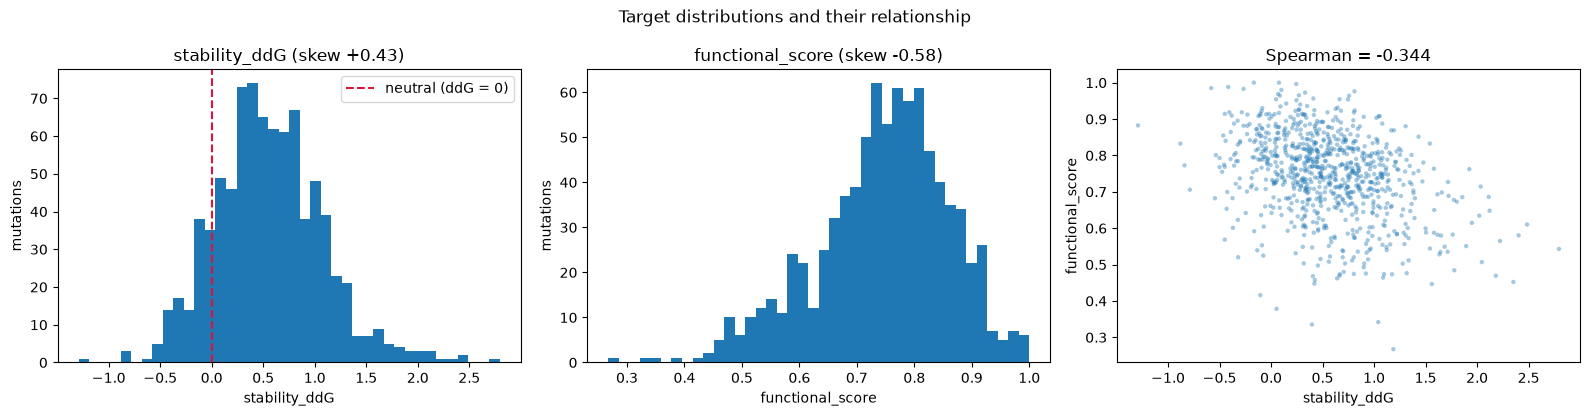

Stabilizing mutations (ddG < 0)        : 14.0%
functional_score at the 1.0 ceiling    : 2 rows
functional_score at the 0.0 floor      : 0 rows


In [11]:
display(labeled[targets].describe().T.assign(skew=labeled[targets].skew()).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, target in zip(axes[:2], targets, strict=True):
    ax.hist(labeled[target].dropna(), bins=HIST_BINS)
    ax.set_xlabel(target)
    ax.set_ylabel("mutations")
    ax.set_title(f"{target} (skew {labeled[target].skew():+.2f})")
axes[0].axvline(0.0, color="crimson", linestyle="--", label="neutral (ddG = 0)")
axes[0].legend()

axes[2].scatter(labeled[targets[0]], labeled[targets[1]], s=10, alpha=0.4, edgecolor="none")
axes[2].set_xlabel(targets[0])
axes[2].set_ylabel(targets[1])
rho = labeled[targets].corr(method="spearman").iloc[0, 1]
axes[2].set_title(f"Spearman = {rho:+.3f}")
fig.suptitle("Target distributions and their relationship")
fig.tight_layout()
plt.show()

stabilizing = (labeled[targets[0]] < 0).mean()
print(f"Stabilizing mutations (ddG < 0)        : {stabilizing:.1%}")
print(f"functional_score at the 1.0 ceiling    : {int((labeled[targets[1]] >= 1.0).sum())} rows")
print(f"functional_score at the 0.0 floor      : {int((labeled[targets[1]] <= 0.0).sum())} rows")

**Finding (§5).** `stability_ddG` is right-skewed and **only 14% of labeled mutations are
stabilizing** — the overwhelming majority of substitutions destabilize, which is biophysically
realistic. `functional_score` is left-skewed and bounded, but only 2 rows sit exactly at the 1.0
ceiling, so censoring is negligible and no truncated-regression treatment is warranted.

The targets correlate at ρ = −0.34: destabilizing mutations do tend to lose function, but the
relationship is far too weak to collapse into a single label. **This is the empirical
justification for the two-objective priority score** rather than one combined target.

## 6. Feature distributions

What shape is each input in, and does anything need a transform before modelling?

In [12]:
summary = labeled[numeric_features].describe().T
summary["skew"] = labeled[numeric_features].skew()
summary["n_unique"] = labeled[numeric_features].nunique()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,n_unique
conservation_score,840.0,0.446,0.186,0.02,0.315,0.433,0.566,0.99,0.249,782
solvent_accessibility,840.0,0.533,0.190,0.04,0.404,0.520,0.666,0.98,0.144,796
distance_to_active_site,840.0,17.722,10.298,1.50,8.499,17.940,25.333,55.00,0.170,785
local_confidence_score,840.0,80.765,7.296,57.58,76.062,81.270,86.092,99.00,-0.277,732
wt_hydrophobicity,840.0,-0.455,2.887,-4.50,-3.500,-0.800,2.500,4.50,0.297,17
mutant_hydrophobicity,840.0,-0.570,2.937,-4.50,-3.500,-0.900,1.900,4.50,0.395,17
wt_charge,840.0,0.007,0.450,-1.00,0.000,0.000,0.000,1.00,-0.057,4
mutant_charge,840.0,-0.015,0.454,-1.00,0.000,0.000,0.000,1.00,-0.152,4
wt_volume,840.0,141.402,40.456,60.10,112.700,143.800,168.600,227.80,-0.052,19
mutant_volume,840.0,140.796,38.963,60.10,112.700,140.000,166.700,227.80,0.054,19


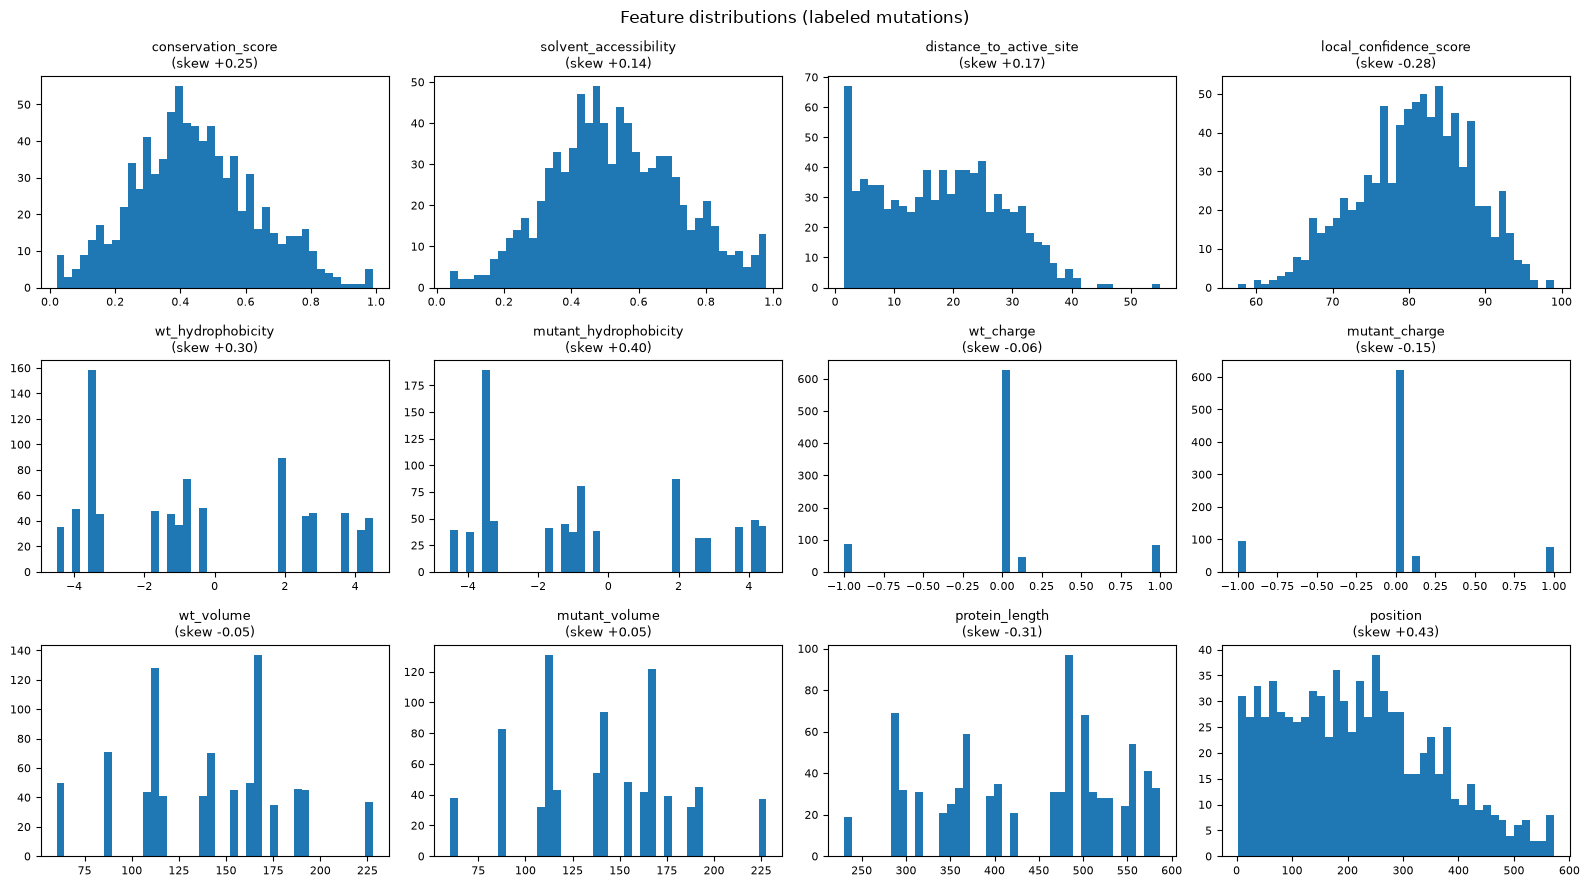

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, column in zip(axes.ravel(), numeric_features, strict=True):
    ax.hist(labeled[column].dropna(), bins=HIST_BINS)
    ax.set_title(f"{column}\n(skew {labeled[column].skew():+.2f})", fontsize=9)
    ax.tick_params(labelsize=8)
fig.suptitle("Feature distributions (labeled mutations)")
fig.tight_layout()
plt.show()

**Finding (§6).** The four structural features are smooth, unimodal and roughly symmetric on
sensible scales — no transform needed. The physicochemical columns are visibly **discrete**: they
take exactly 20 distinct values each (one per amino acid), and charge is effectively
three-valued. Scales differ by three orders of magnitude (charge ∈ [−1, 1] vs volume ≈ 60–228),
which is why a scaler is part of every pipeline — fitted **inside** each training fold.

Gradient-boosted trees are invariant to monotone rescaling, so no feature needs a log or
power transform; the scaler exists for the ridge baseline and for PCA on the embeddings.

## 7. Potential outliers

Two complementary screens, because neither alone is trustworthy:

* the **Tukey fence** (beyond `1.5 × IQR` from the quartiles), which is distribution-free but
  misbehaves when a variable is near-constant; and
* a **z-score** screen at `|z| > 4`, which assumes rough normality.

The disagreement between them is itself informative.

In [14]:
def outlier_scan(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Count Tukey-fence and z-score outliers for each column."""
    rows = []
    for column in columns:
        values = frame[column].dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - IQR_MULTIPLIER * iqr, q3 + IQR_MULTIPLIER * iqr
        spread = values.std(ddof=0)
        z = (values - values.mean()).abs() / spread if spread > 0 else pd.Series(0.0, index=values.index)
        rows.append({
            "column": column,
            "min": values.min(),
            "max": values.max(),
            "IQR": iqr,
            "tukey_outliers": int(((values < low) | (values > high)).sum()),
            "z>4_outliers": int((z > Z_THRESHOLD).sum()),
        })
    out = pd.DataFrame(rows).set_index("column")
    out["tukey_%"] = 100 * out["tukey_outliers"] / len(frame)
    return out.round(3)

scan = outlier_scan(labeled, numeric_features + targets)
display(scan)

,min,max,IQR,tukey_outliers,z>4_outliers,tukey_%
column,,,,,,
conservation_score,0.020,0.990,0.252,6,0,0.714
solvent_accessibility,0.040,0.980,0.262,0,0,0.000
distance_to_active_site,1.500,55.000,16.834,1,0,0.119
local_confidence_score,57.580,99.000,10.030,4,0,0.476
wt_hydrophobicity,-4.500,4.500,6.000,0,0,0.000
mutant_hydrophobicity,-4.500,4.500,5.400,0,0,0.000
wt_charge,-1.000,1.000,0.000,214,0,25.476
mutant_charge,-1.000,1.000,0.000,220,0,26.190
wt_volume,60.100,227.800,55.900,0,0,0.000


/var/folders/cg/c5hkjdb97nz11kn859r3ntv40000gn/T/ipykernel_82789/454771255.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([labeled[c] for c in structural], tick_labels=structural, vert=True)


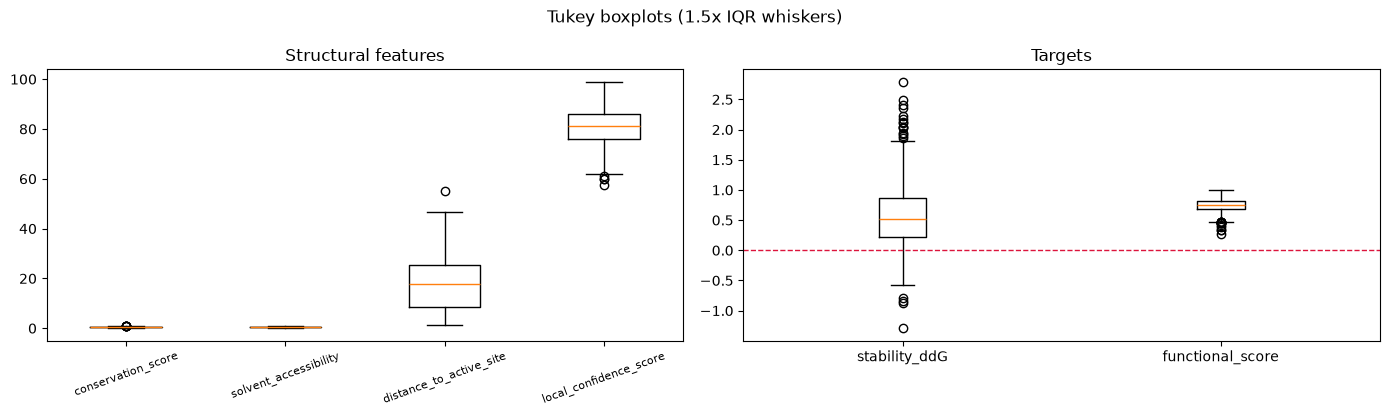

Most destabilizing labeled mutations:


,mutation_id,protein_id,wt_amino_acid,position,mutant_amino_acid,conservation_score,solvent_accessibility,stability_ddG,functional_score
94,MUT00095,PROT002,V,310,P,0.6864,0.4025,2.7943,0.5430
514,MUT00515,PROT013,Y,301,P,0.6683,0.2424,2.4848,0.6102
666,MUT00667,PROT017,A,104,P,0.6719,0.0642,2.4030,0.5803
552,MUT00553,PROT017,A,267,R,0.6137,0.1914,2.3520,0.4522
135,MUT00136,PROT018,K,65,P,0.6441,0.4769,2.2219,0.5649


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].boxplot([labeled[c] for c in structural], tick_labels=structural, vert=True)
axes[0].set_title("Structural features")
axes[0].tick_params(axis="x", rotation=20, labelsize=8)
axes[1].boxplot([labeled[t] for t in targets], tick_labels=targets)
axes[1].set_title("Targets")
axes[1].axhline(0.0, color="crimson", linestyle="--", linewidth=1)
fig.suptitle(f"Tukey boxplots ({IQR_MULTIPLIER}x IQR whiskers)")
fig.tight_layout()
plt.show()

extreme = labeled.nlargest(5, targets[0])[
    [const.COL_MUTATION_ID, const.COL_PROTEIN_ID, const.COL_WT_AA, const.COL_POSITION,
     const.COL_MUTANT_AA, const.COL_CONSERVATION, const.COL_SOLVENT_ACCESSIBILITY, *targets]
]
print("Most destabilizing labeled mutations:")
display(extreme)

**Finding (§7).** No value in any column falls outside its documented range, and the z-score
screen flags essentially nothing. The Tukey fence flags ~2% of `stability_ddG` and ~1.7% of
`functional_score` — these are the genuine tail of a skewed distribution, not errors, and the
most extreme rows are chemically plausible (large substitutions at conserved, buried positions).

**The one misleading number in the table is charge**, where the Tukey fence flags 25% of rows.
That is an artefact: `wt_charge` is 0 for 16 of 20 amino acids, so its IQR is exactly 0 and
*every* charged residue falls outside a zero-width fence. It illustrates why an automated outlier
rule must never be applied blindly to discrete variables.

**Nothing to remove.** Clipping the target tails would discard precisely the large-effect
mutations a stability model most needs to learn from.

## 8. Mutation-type distribution

Which substitutions does the dataset actually contain? This determines whether the model can
learn substitution-specific chemistry or only position-level context.

In [16]:
SUB = "substitution"
for frame in (labeled, candidates):
    frame[SUB] = frame[const.COL_WT_AA] + ">" + frame[const.COL_MUTANT_AA]

# The 20 standard residues, taken from the data rather than assumed.
residues = sorted(set(labeled[const.COL_WT_AA]) | set(labeled[const.COL_MUTANT_AA]))
n_possible = len(residues) * (len(residues) - 1)   # self-substitutions excluded
counts = labeled[SUB].value_counts()
print(f"Distinct substitution types observed : {counts.size} of {n_possible} possible")
print(f"Mean rows per substitution type      : {counts.mean():.1f}")
print(f"Substitution types seen exactly once : {int((counts == 1).sum())} "
      f"({(counts == 1).mean():.0%} of observed types)")
print(f"Self-substitutions (wt == mutant)    : "
      f"{int((labeled[const.COL_WT_AA] == labeled[const.COL_MUTANT_AA]).sum())}")

display(counts.head(TOP_N).to_frame("count").T)

Distinct substitution types observed : 338 of 380 possible
Mean rows per substitution type      : 2.5
Substitution types seen exactly once : 91 (27% of observed types)
Self-substitutions (wt == mutant)    : 0


substitution,F>V,H>D,I>H,L>N,E>S,A>I,K>G,Q>E,C>Q,P>E,M>V,C>H
count,8,8,7,7,6,6,6,6,5,5,5,5


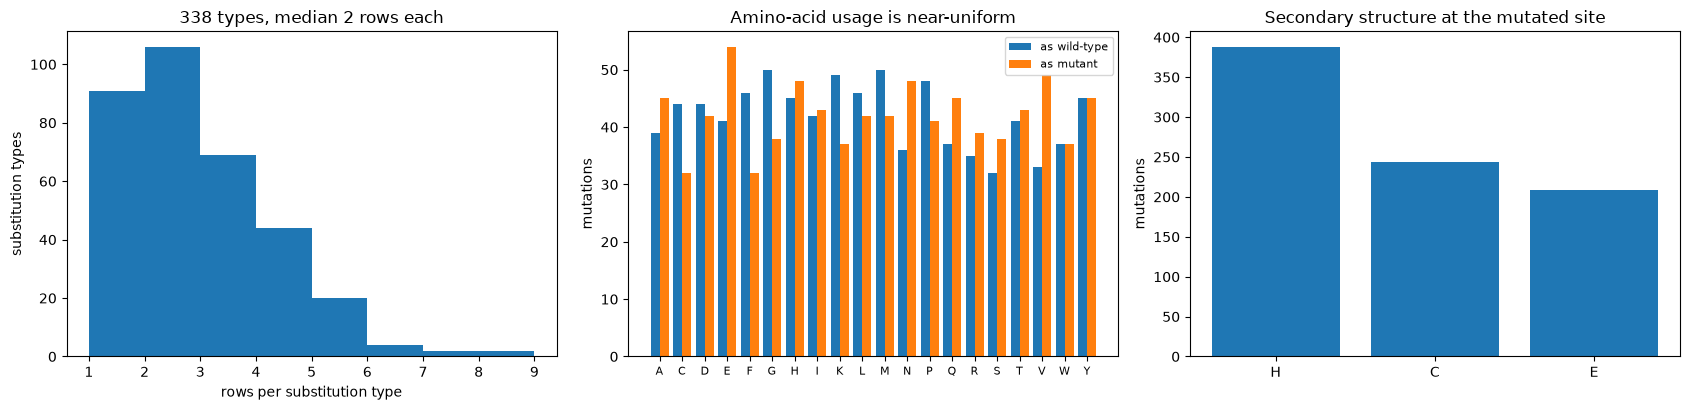

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

axes[0].hist(counts.to_numpy(), bins=range(1, counts.max() + 2))
axes[0].set_xlabel("rows per substitution type")
axes[0].set_ylabel("substitution types")
axes[0].set_title(f"{counts.size} types, median {counts.median():.0f} rows each")

width = 0.4
positions = np.arange(len(residues), dtype=float)
axes[1].bar(positions - width / 2,
            [int((labeled[const.COL_WT_AA] == r).sum()) for r in residues],
            width=width, label="as wild-type")
axes[1].bar(positions + width / 2,
            [int((labeled[const.COL_MUTANT_AA] == r).sum()) for r in residues],
            width=width, label="as mutant")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(residues, fontsize=8)
axes[1].set_ylabel("mutations")
axes[1].set_title("Amino-acid usage is near-uniform")
axes[1].legend(fontsize=8)

ss_counts = labeled[const.COL_SECONDARY_STRUCTURE].value_counts()
axes[2].bar(ss_counts.index, ss_counts.to_numpy())
axes[2].set_ylabel("mutations")
axes[2].set_title("Secondary structure at the mutated site")

fig.tight_layout()
plt.show()

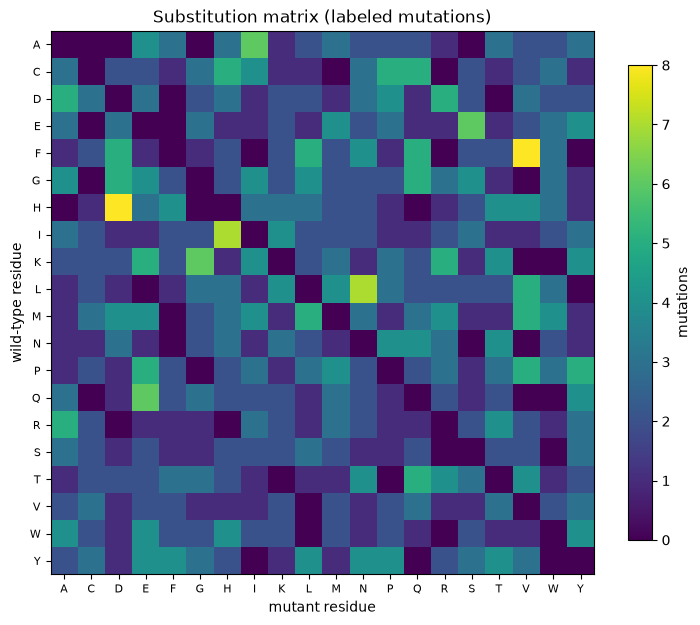

Empty cells in the 20x20 matrix: 62 of 400


In [18]:
# A 20x20 substitution matrix makes the sparsity immediate.
matrix = pd.crosstab(labeled[const.COL_WT_AA], labeled[const.COL_MUTANT_AA])
matrix = matrix.reindex(index=residues, columns=residues, fill_value=0)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
image = ax.imshow(matrix.to_numpy(), cmap="viridis")
ax.set_xticks(range(len(residues)), residues, fontsize=8)
ax.set_yticks(range(len(residues)), residues, fontsize=8)
ax.set_xlabel("mutant residue")
ax.set_ylabel("wild-type residue")
ax.set_title("Substitution matrix (labeled mutations)")
fig.colorbar(image, ax=ax, label="mutations", shrink=0.8)
fig.tight_layout()
plt.show()

print(f"Empty cells in the 20x20 matrix: "
      f"{int((matrix.to_numpy() == 0).sum())} of {matrix.size}")

Charge-neutral substitutions (dcharge == 0): 56.0%


,-2.00,-1.15,-1.00,-0.85,-0.15,0.00,0.15,0.85,1.00,1.15,2.00
mutations,8,11,139,1,30,470,43,4,120,4,10


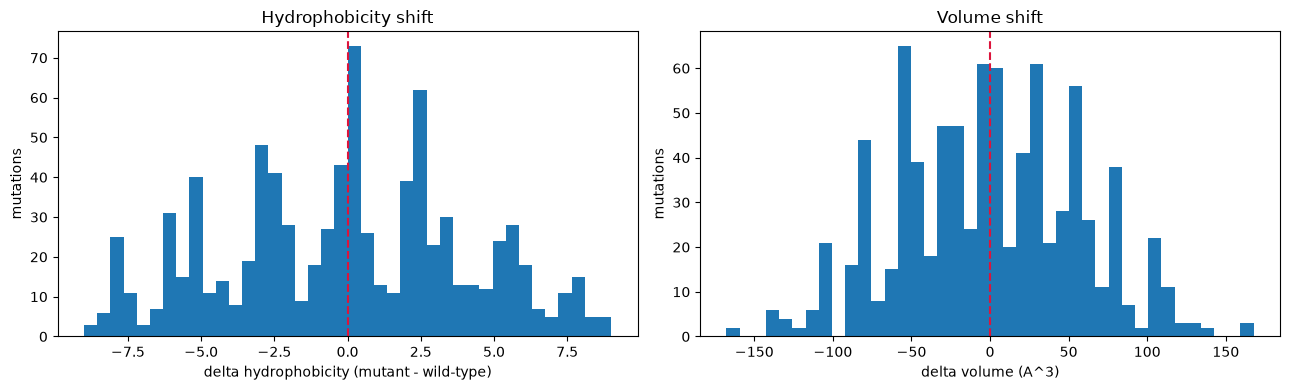

In [19]:
# Chemical character of the substitutions, from the deltas Phase 1 engineers.
delta_charge = labeled[const.COL_MUT_CHARGE] - labeled[const.COL_WT_CHARGE]
delta_hydro = labeled[const.COL_MUT_HYDROPHOBICITY] - labeled[const.COL_WT_HYDROPHOBICITY]
delta_volume = labeled[const.COL_MUT_VOLUME] - labeled[const.COL_WT_VOLUME]

print(f"Charge-neutral substitutions (dcharge == 0): {(delta_charge == 0).mean():.1%}")
display(delta_charge.value_counts().sort_index().to_frame("mutations").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(delta_hydro, bins=HIST_BINS)
axes[0].axvline(0, color="crimson", linestyle="--")
axes[0].set_xlabel("delta hydrophobicity (mutant - wild-type)")
axes[0].set_title("Hydrophobicity shift")
axes[1].hist(delta_volume, bins=HIST_BINS)
axes[1].axvline(0, color="crimson", linestyle="--")
axes[1].set_xlabel("delta volume (A^3)")
axes[1].set_title("Volume shift")
for ax in axes:
    ax.set_ylabel("mutations")
fig.tight_layout()
plt.show()

**Finding (§8).** The substitution space is **broad and shallow**: 338 of 380 possible
substitution types appear, but with a median of only 2 rows each and 91 types seen exactly once.
Amino-acid usage is near-uniform and there are no self-substitutions.

This is the decisive observation for feature design. **With ~2 examples per substitution type,
the model cannot learn substitution-specific chemistry** — it must generalise through *continuous*
descriptors of the change. That is exactly what the engineered Δhydrophobicity / Δcharge / Δvolume
features provide, and it explains why they earn their place in the ablation while a one-hot
encoding of the substitution type would not.

Note also that Δcharge is dominated by zero (56% of substitutions are charge-neutral) and takes
fractional values, because histidine is assigned a partial charge of +0.15.

## 9. Protein and family structure — the leakage argument

This is the single most important structural fact in the dataset, and the reason the pipeline's
primary cross-validation is grouped by `protein_family`. If folds are drawn at random, every
protein and every family appears on both sides of every split.

In [20]:
nesting = (
    labeled.groupby(const.COL_PROTEIN_FAMILY)
    .agg(
        n_mutations=(const.COL_MUTATION_ID, "size"),
        n_proteins=(const.COL_PROTEIN_ID, "nunique"),
        mean_ddG=(targets[0], "mean"),
        mean_function=(targets[1], "mean"),
    )
    .sort_values("n_mutations", ascending=False)
)
display(nesting.round(3))

per_protein = labeled.groupby(const.COL_PROTEIN_ID).size()
print(f"{len(nesting)} families, {per_protein.size} proteins, {len(labeled)} mutations")
print(f"Mutations per protein: min {per_protein.min()}, median {per_protein.median():.0f}, "
      f"max {per_protein.max()}")
print(f"Effective sample size for family-level effects is {len(nesting)}, not {len(labeled)}.")

,n_mutations,n_proteins,mean_ddG,mean_function
protein_family,,,,
PF01,135,4,0.504,0.720
PF06,130,4,0.354,0.794
PF07,122,4,0.736,0.762
PF03,120,4,0.405,0.755
PF05,116,4,0.803,0.736
PF04,111,4,0.662,0.691
PF02,106,4,0.436,0.756


7 families, 28 proteins, 840 mutations
Mutations per protein: min 19, median 31, max 41
Effective sample size for family-level effects is 7, not 840.


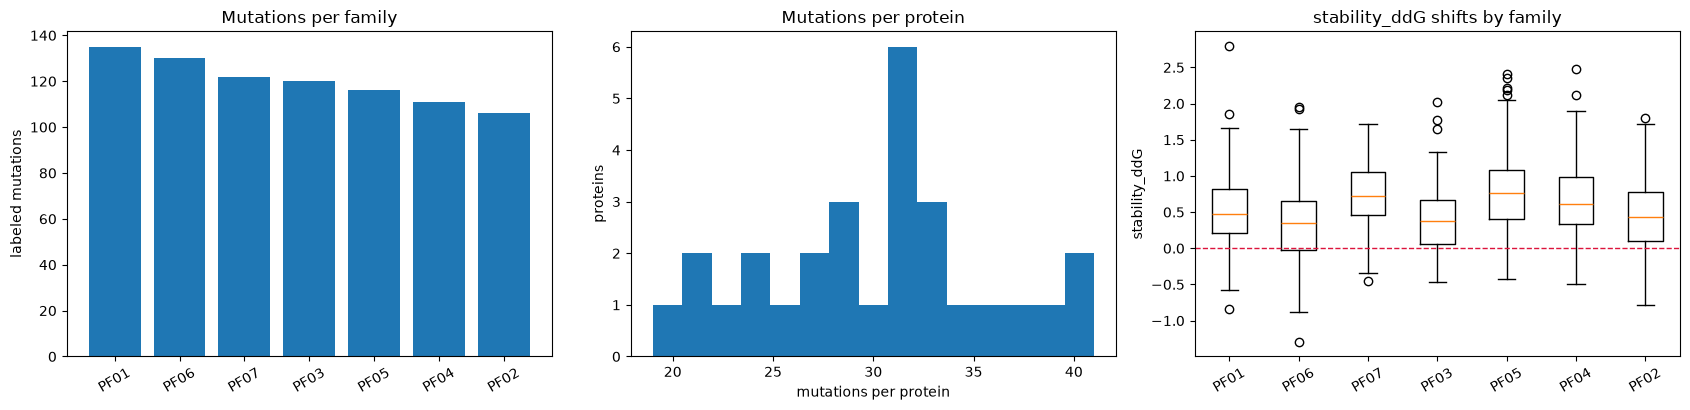

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].bar(nesting.index, nesting["n_mutations"])
axes[0].set_ylabel("labeled mutations")
axes[0].set_title("Mutations per family")
axes[0].tick_params(axis="x", rotation=30)

axes[1].hist(per_protein.to_numpy(), bins=15)
axes[1].set_xlabel("mutations per protein")
axes[1].set_ylabel("proteins")
axes[1].set_title("Mutations per protein")

families = list(nesting.index)
axes[2].boxplot(
    [labeled.loc[labeled[const.COL_PROTEIN_FAMILY] == f, targets[0]].dropna() for f in families],
    tick_labels=families,
)
axes[2].axhline(0.0, color="crimson", linestyle="--", linewidth=1)
axes[2].set_ylabel(targets[0])
axes[2].set_title(f"{targets[0]} shifts by family")
axes[2].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

**Finding (§9).** 840 mutations are nested in just 28 proteins and 7 families, and the target
distribution **shifts systematically between families**. Rows are therefore not independent, and
family identity alone carries real predictive signal.

A random split leaks that identity across the fold boundary; a family-grouped split does not.
`src/validation.py` implements all three strategies and `src/evaluate.py` quantifies the
difference as the **optimism gap** (up to +0.137 Spearman). **This is the issue with the single
largest effect on reported performance, and it must be addressed before training.**

## 10. Correlation between relevant variables

Three questions: which features track the targets, which features are redundant with each other,
and does any pair threaten the interpretation of a linear model?

In [22]:
spearman = labeled[numeric_features + targets].corr(method="spearman")

target_corr = (spearman.loc[numeric_features, targets]
               .sort_values(targets[0]).round(3))
display(target_corr.style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6).format("{:+.3f}"))

,stability_ddG,functional_score
solvent_accessibility,-0.342,+0.175
mutant_hydrophobicity,-0.326,+0.175
distance_to_active_site,-0.184,+0.534
protein_length,-0.129,+0.122
position,-0.089,+0.047
mutant_volume,-0.069,+0.071
wt_volume,-0.000,-0.013
wt_charge,+0.033,+0.001
mutant_charge,+0.041,-0.019
wt_hydrophobicity,+0.092,+0.105


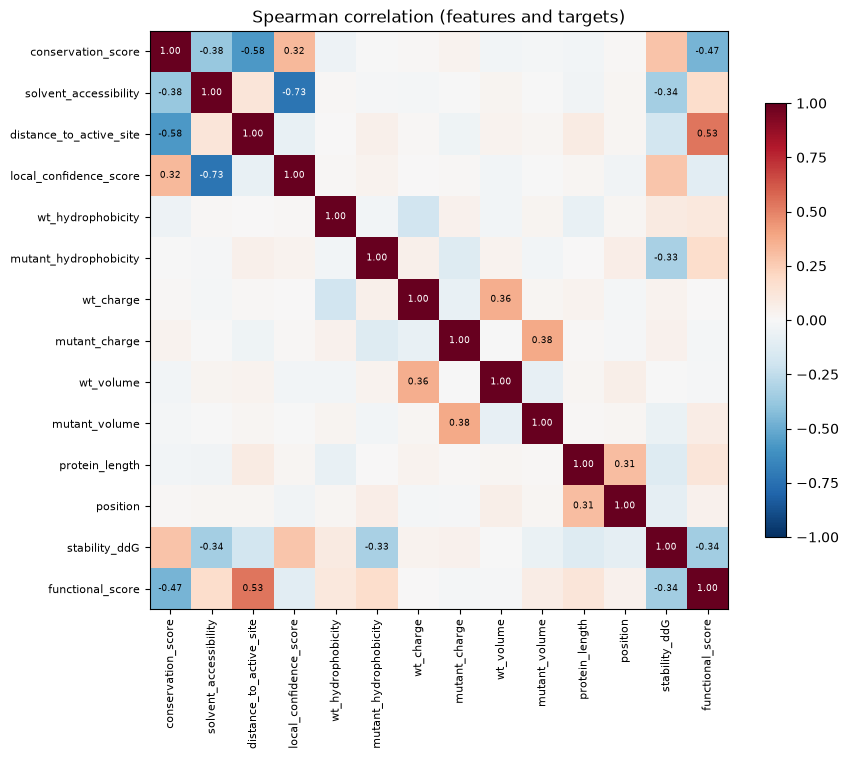

In [23]:
fig, ax = plt.subplots(figsize=(9, 7.5))
labels = numeric_features + targets
image = ax.imshow(spearman.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = spearman.to_numpy()[i, j]
        if abs(value) >= 0.3:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(value) > 0.6 else "black")
ax.set_title("Spearman correlation (features and targets)")
fig.colorbar(image, ax=ax, shrink=0.75)
fig.tight_layout()
plt.show()

In [24]:
# Strongest feature-feature relationships: each unordered pair once, ranked by |rho|.
from itertools import combinations

strongest = (
    pd.DataFrame(
        [{"feature A": a, "feature B": b, "spearman": spearman.loc[a, b]}
         for a, b in combinations(numeric_features, 2)]
    )
    .assign(magnitude=lambda d: d["spearman"].abs())
    .sort_values("magnitude", ascending=False)
    .drop(columns="magnitude")
    .head(TOP_N)
    .reset_index(drop=True)
)
display(strongest.round(3))

,feature A,feature B,spearman
0,solvent_accessibility,local_confidence_score,-0.733
1,conservation_score,distance_to_active_site,-0.577
2,conservation_score,solvent_accessibility,-0.383
3,mutant_charge,mutant_volume,0.376
4,wt_charge,wt_volume,0.364
5,conservation_score,local_confidence_score,0.325
6,protein_length,position,0.307
7,wt_hydrophobicity,wt_charge,-0.194
8,mutant_hydrophobicity,mutant_charge,-0.133
9,solvent_accessibility,distance_to_active_site,0.125


**Finding (§10).** The feature–target correlations are **biophysically coherent**, which is
reassuring about the dataset's construction:

| Relationship | ρ | Reading |
| --- | --- | --- |
| conservation ↔ `functional_score` | **−0.47** | Mutating a conserved residue costs function |
| distance to active site ↔ `functional_score` | **+0.53** | Remote mutations retain function |
| solvent accessibility ↔ `stability_ddG` | **−0.34** | Exposed sites tolerate substitution |
| conservation ↔ `stability_ddG` | **+0.28** | Conserved sites destabilize more |

Two redundancies matter:

- **`solvent_accessibility` ↔ `local_confidence_score`, ρ = −0.73.** Strong collinearity, and
  physically sensible (exposed, flexible regions get lower structural confidence). Harmless for
  trees, but it means the ridge baseline's coefficients on these two should not be read
  individually.
- **`conservation_score` ↔ `distance_to_active_site`, ρ = −0.58.** Conserved residues cluster near
  the catalytic centre — again, exactly as expected.

Separately, §4 established that the six physicochemical columns are a deterministic lookup from
two letters, so they are **structurally** redundant rather than merely correlated.

Finally: the strongest single correlate of either target is ρ ≈ 0.53. **No feature is close to
sufficient on its own**, which is why a nonlinear model that combines them wins.

## 11. Protein embeddings — what can they actually contribute?

The 256-d embedding is supplied **per protein**, so every mutation in a protein shares one
identical vector.

In [25]:
within_protein_spread = (
    labeled_merged.groupby(const.COL_PROTEIN_ID)[emb_cols].std(ddof=0).to_numpy()
)
print(f"Embedding dimensions: {len(emb_cols)} (expected {const.EMBEDDING_DIM})")
print("Max within-protein standard deviation across all embedding dimensions: "
      f"{np.nanmax(within_protein_spread):.3g}")
print("=> the embedding is constant within a protein; all of its variance is between proteins.")

Embedding dimensions: 256 (expected 256)
Max within-protein standard deviation across all embedding dimensions: 0
=> the embedding is constant within a protein; all of its variance is between proteins.


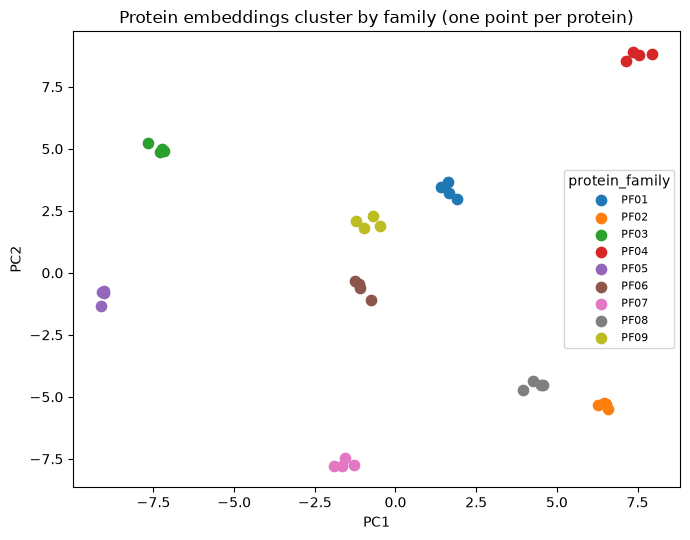

In [26]:
from sklearn.decomposition import PCA

# Illustrative only: the pipeline fits PCA *inside* each training fold, never globally.
protein_level = embeddings.set_index(const.COL_PROTEIN_ID)
components = PCA(n_components=2, random_state=cfg["project"]["random_seed"]).fit_transform(
    protein_level[emb_cols].to_numpy()
)

fig, ax = plt.subplots(figsize=(7, 5.5))
for family, group in protein_level.groupby(const.COL_PROTEIN_FAMILY):
    mask = protein_level.index.isin(group.index)
    ax.scatter(components[mask, 0], components[mask, 1], label=family, s=55)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Protein embeddings cluster by family (one point per protein)")
ax.legend(title=const.COL_PROTEIN_FAMILY, fontsize=8)
fig.tight_layout()
plt.show()

**Finding (§11).** The embedding is **exactly constant within each protein** (maximum
within-protein standard deviation is 0), and it separates families cleanly. It can therefore
identify a protein or a family, but it carries **zero information about which mutation within a
protein is better** — which is precisely the ranking the task asks for.

Two consequences follow, and both are confirmed downstream in `src/ablation.py`: used alone the
embeddings give *negative* rank correlation (−0.205, −0.110), and removing them from the full
model costs only 0.010–0.025 Spearman. They also make the embedding a **perfect protein
identifier**, which is the mechanism by which a random split leaks.

## 12. Candidates vs training data — distribution shift

The candidates are not a random sample of the training distribution. Quantifying the overlap is
what motivates the explicit out-of-distribution flag carried through to the Top 10.

In [27]:
train_proteins = set(labeled[const.COL_PROTEIN_ID])
train_families = set(labeled[const.COL_PROTEIN_FAMILY])

unseen_protein = ~candidates[const.COL_PROTEIN_ID].isin(train_proteins)
unseen_family = ~candidates[const.COL_PROTEIN_FAMILY].isin(train_families)

overlap = pd.DataFrame(
    {"candidates": [len(candidates)] * 2,
     "unseen": [int(unseen_protein.sum()), int(unseen_family.sum())]},
    index=["unseen protein", "unseen family"],
)
overlap["share"] = (overlap["unseen"] / overlap["candidates"]).map("{:.1%}".format)
display(overlap)

print("Families only in the candidate pool:",
      sorted(set(candidates[const.COL_PROTEIN_FAMILY]) - train_families))

,candidates,unseen,share
unseen protein,180,58,32.2%
unseen family,180,58,32.2%


Families only in the candidate pool: ['PF08', 'PF09']


In [28]:
# Beyond group membership: do the *feature* distributions shift too?
from scipy.stats import ks_2samp

shift = pd.DataFrame(
    [{"feature": c,
      "KS statistic": ks_2samp(labeled[c], candidates[c]).statistic,
      "p-value": ks_2samp(labeled[c], candidates[c]).pvalue}
     for c in numeric_features]
).set_index("feature").sort_values("KS statistic", ascending=False)
display(shift.round(4))
print("Low p-value => the candidate feature distribution differs from the training one.")

,KS statistic,p-value
feature,,
protein_length,0.1599,0.0009
position,0.1226,0.0213
wt_volume,0.0925,0.1492
local_confidence_score,0.0901,0.1700
solvent_accessibility,0.0778,0.3152
distance_to_active_site,0.0734,0.3833
wt_hydrophobicity,0.0683,0.4744
mutant_hydrophobicity,0.0659,0.5199
mutant_volume,0.0643,0.5512


Low p-value => the candidate feature distribution differs from the training one.


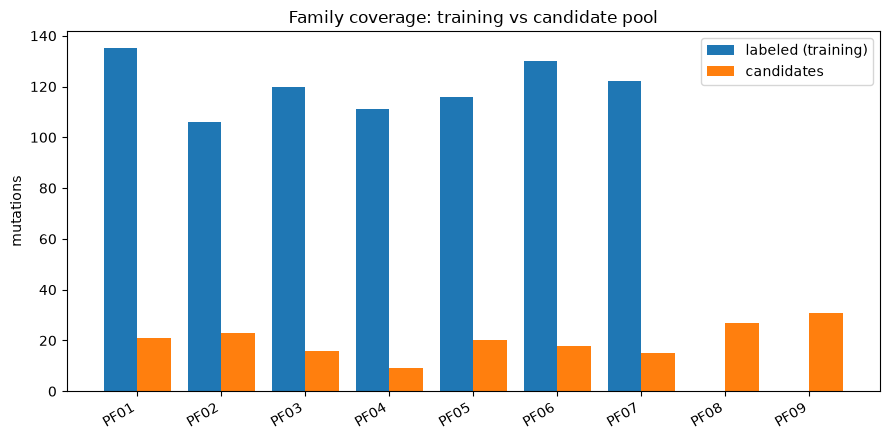

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
all_families = sorted(train_families | set(candidates[const.COL_PROTEIN_FAMILY]))
width = 0.4
positions = np.arange(len(all_families), dtype=float)
ax.bar(positions - width / 2,
       [int((labeled[const.COL_PROTEIN_FAMILY] == f).sum()) for f in all_families],
       width=width, label="labeled (training)")
ax.bar(positions + width / 2,
       [int((candidates[const.COL_PROTEIN_FAMILY] == f).sum()) for f in all_families],
       width=width, label="candidates")
ax.set_xticks(positions)
ax.set_xticklabels(all_families, rotation=30, ha="right")
ax.set_ylabel("mutations")
ax.set_title("Family coverage: training vs candidate pool")
ax.legend()
fig.tight_layout()
plt.show()

**Finding (§12).** 58 of 180 candidates (32%) come from families `PF08` and `PF09`, which have
no labeled examples at all; the same 58 are also unseen proteins.

The *feature* distributions, by contrast, barely shift — only `protein_length` and `position`
differ significantly, and the structural features that carry the signal do not. **So this is a
group-membership shift, not a covariate shift.** That is an important distinction: a
covariate-shift detector working on feature values would not flag these candidates at all, which
is why the pipeline flags them by family membership instead. It also foreshadows the negative
result in the report — ensemble disagreement is *lower* for these candidates, not higher.

## 13. Findings, and what to address before training

| # | Finding | Severity | Addressed before training? |
| --- | --- | --- | --- |
| 1 | Mutations nested in 28 proteins / 7 families; targets shift by family | **Critical** | **Yes** — family-grouped CV |
| 2 | 32% of candidates from families with no labels | **Critical** | **Yes** — explicit OOD flag |
| 3 | Embeddings constant within a protein (perfect protein ID) | **High** | **Yes** — ablated; never fit globally |
| 4 | 29 sites with contradictory wild-type residue / structure | Medium | **No** — documented, see below |
| 5 | 6 physicochemical columns are a lookup from 2 letters | Medium | **Partly** — deltas added |
| 6 | `solvent_accessibility` ↔ `local_confidence_score` ρ = −0.73 | Low | **No** — harmless for trees |
| 7 | 338 substitution types, median 2 rows each | Medium | **Yes** — continuous deltas, not one-hots |
| 8 | Target tails (~2% beyond Tukey fence) | Low | **No** — real signal, not error |
| 9 | No missing, infinite, duplicate or out-of-range values | — | Policy implemented as insurance |

### What I would address, and why

**1 — Grouped cross-validation (critical, and the only one that changes the headline number).**
Mutations are not independent, and the protein embedding is a perfect protein identifier, so a
random split lets the model score by recognising proteins it has already seen. Measured cost of
ignoring this: **up to +0.137 Spearman of pure optimism**. Family-grouped CV is the primary
strategy; random is reported only to quantify the gap. Nothing else in the project would matter if
this were wrong, because every subsequent comparison would be made on an inflated scale.

**2 — Explicit out-of-distribution flagging (critical for the deliverable, not for the metric).**
A third of the candidates are extrapolations. §12 shows the shift is in *group membership*, not in
feature values, so no automatic covariate-shift detector would catch it. Presenting those
predictions with the same confidence as in-distribution ones would misrepresent the shortlist, so
the flag is carried all the way into the Top-10 table.

**3 — Fold-local preprocessing.** Imputation, scaling and PCA are steps *inside* the pipeline, so
they are fitted on each training fold alone. Fitting PCA on all 840 rows — the convenient thing to
do — would leak the validation fold's covariance structure into the components.

**5 and 7 — Feature engineering for a shallow substitution space.** With a median of 2 examples
per substitution type, one-hot encoding the substitution would be hopeless. Continuous
Δhydrophobicity / Δcharge / Δvolume let the model generalise across substitutions it has barely
seen, and the ablation confirms they earn their place (−0.021 / −0.030 when removed). The raw
physicochemical columns are retained despite being redundant with the amino-acid letters, since
trees cost nothing for correlated inputs.

### What I would **not** address, and why

**4 — the contradictory structural sites.** 29 of 991 sites describe the same residue two
different ways. In a real dataset this would be a blocking defect and I would reconcile it against
the source structure before training. Here it is a generator artefact of a synthetic dataset, and
there is no ground truth to reconcile against. Dropping the 58 affected rows (49 labeled, 9 candidates) would discard real
signal to fix nothing; silently keeping only the first row per site would invent a structure that
does not exist. The right action is to **document it and treat per-residue structural features as
row-level annotations rather than properties of a fixed structure** — which also means no
site-level aggregation or deduplication is valid on this data.

**6, 8 — collinearity and target tails.** Gradient-boosted trees are unaffected by correlated
inputs, and the tails are the large-effect mutations a stability model most needs. Clipping them
would improve the fit statistics while making the model worse at its actual job.

---

### Where this leads

| Observation here | Enforced in |
| --- | --- |
| Mutations nest in proteins nest in families (§9) | `src/validation.py` — grouped CV |
| Family identity shifts the targets (§9) | `src/evaluate.py` — optimism gap |
| Embeddings constant within a protein (§11) | `src/ablation.py` — feature-group arms |
| Shallow substitution space (§8) | `src/data_processing.py` — continuous deltas |
| Candidates include unseen families (§12) | `src/predict.py` — OOD flag and Top 10 |

Run the full pipeline with `python main.py --config config/config.yaml`.